In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
churn = pd.read_csv("drive/MyDrive/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [43]:
churn

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Unnamed: 21
0,2775-SEFEE,Male,0,No,Yes,0,Yes,Yes,DSL,Yes,...,Yes,No,No,Two year,Yes,Bank transfer (automatic),61.90,18.80,No,11
1,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,18.85,No,FALSE
2,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,No,Two year,No,Mailed check,73.35,18.85,No,NaN
3,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,18.90,No,NaN
4,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,19.00,No,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,4667-OHGKG,Male,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,19.30,8496.70,Yes,NaN
7039,0761-AETCS,Female,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,Month-to-month,No,Electronic check,19.30,8543.25,Yes,NaN
7040,5510-BOIUJ,Male,0,No,Yes,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.25,8564.75,Yes,NaN
7041,9318-NKNFC,Male,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,18.85,NaN,Yes,NaN


In [44]:
churn.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Unnamed: 21
0,2775-SEFEE,Male,0,No,Yes,0,Yes,Yes,DSL,Yes,...,Yes,No,No,Two year,Yes,Bank transfer (automatic),61.90,18.80,No,11
1,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,18.85,No,FALSE
2,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,No,Two year,No,Mailed check,73.35,18.85,No,NaN
3,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,18.90,No,NaN
4,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,19.00,No,NaN


In [45]:
churn.TotalCharges.fillna(74, inplace=True)

/tmp/ipykernel_17436/295640861.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  churn.TotalCharges.fillna(74, inplace=True)


In [46]:
churn.TotalCharges.isnull().sum()

np.int64(0)

In [47]:
churn.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'Unnamed: 21'],
      dtype='object')

In [48]:
churn.drop('Unnamed: 21', axis=1, inplace=True)

In [49]:
churn.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [50]:
# What is the overall churn rate?
customer_leave = (churn.Churn == "Yes").sum()
customer = 7043
churn_rate = customer_leave / customer * 100
print(churn_rate)

26.536987079369588


In [51]:
# How does contract type affect churn?
churn.Contract.groupby(churn.Churn).value_counts(normalize=True)
# month-to-month taken by customer are  have a high churn rate

Churn  Contract      
No     Month-to-month    0.429068
       Two year          0.318322
       One year          0.252609
Yes    Month-to-month    0.885500
       One year          0.088818
       Two year          0.025682
Name: proportion, dtype: float64

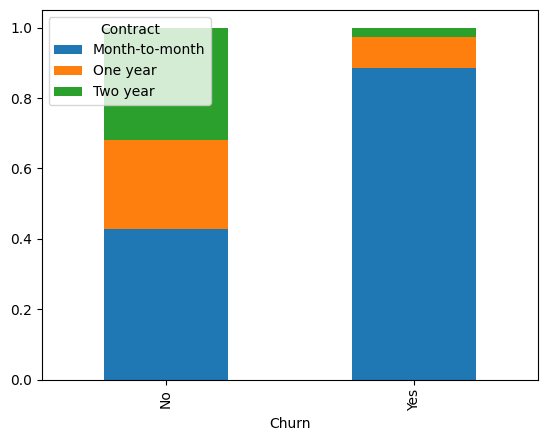

In [52]:
churn.groupby("Churn")["Contract"].value_counts(normalize=True).unstack().plot(kind="bar", stacked=True)

plt.show()

In [53]:
# Do new customers churn more than long-term customers?
churn["Customer_Type"] = churn["tenure"].apply(
    lambda x: "New Customer" if x <= 12 else "Old Customer"
) #  using a lambda function seprate a new and old customerson basis of tenure

In [54]:
print(churn["Customer_Type"].value_counts())

Customer_Type
Old Customer    4857
New Customer    2186
Name: count, dtype: int64


In [55]:
new_customer = churn[(churn["Customer_Type"] == "New Customer")]
old_customer = churn[churn["Customer_Type"] == "Old Customer"]
new_cust_yes = new_customer[new_customer["Churn"] == "Yes"].groupby("Customer_Type").size()
old_cust_yes = old_customer[old_customer["Churn"] == "Yes"].groupby("Customer_Type").size()
new_cust_no = new_customer[new_customer["Churn"] == "No"].groupby("Customer_Type").size()
old_cust_no = old_customer[old_customer["Churn"] == "No"].groupby("Customer_Type").size()
print(new_cust_yes)
print(old_cust_yes)
print(new_cust_no)
print(old_cust_no)

Customer_Type
New Customer    1037
dtype: int64
Customer_Type
Old Customer    832
dtype: int64
Customer_Type
New Customer    1149
dtype: int64
Customer_Type
Old Customer    4025
dtype: int64


In [56]:
new_cust_rate = new_cust_yes / len(new_customer) * 100
old_cust_rate = old_cust_yes / len(old_customer) * 100
print(new_cust_rate)
print(old_cust_rate)

Customer_Type
New Customer    47.438243
dtype: float64
Customer_Type
Old Customer    17.129916
dtype: float64


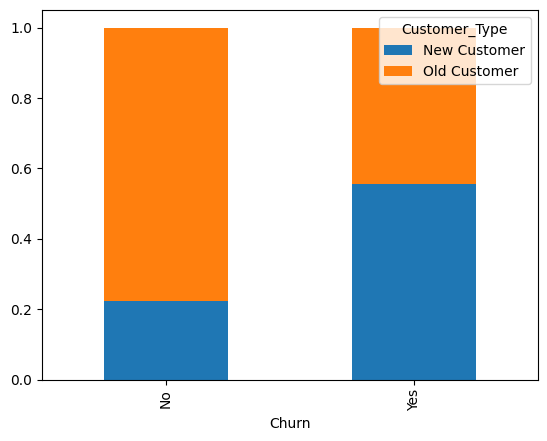

In [57]:
churn.groupby("Churn")["Customer_Type"].value_counts(normalize=True).unstack().plot(kind="bar", stacked=True)

plt.show()

In [58]:
# new term customers churn is more than long term customers, spedifical month-to-month

In [59]:
# Is there a relationship between monthly charges and churn?
churn.MonthlyCharges.groupby(churn.Churn).value_counts(normalize=True)

Churn  MonthlyCharges
No     20.05             0.011210
       19.70             0.007924
       19.95             0.007924
       19.85             0.007731
       19.90             0.007731
                           ...   
Yes    115.65            0.000535
       116.20            0.000535
       117.45            0.000535
       117.80            0.000535
       118.35            0.000535
Name: proportion, Length: 2370, dtype: float64

In [60]:
yes_sum_monthlty_charges = churn.MonthlyCharges.groupby(churn.Churn).min()['Yes']
no_sum_monthlty_charges = churn.MonthlyCharges.groupby(churn.Churn).median()['No']

In [61]:
print(yes_sum_monthlty_charges)
print(no_sum_monthlty_charges.round(2))
# who leave there monthly charges is a more as compare to who don't leave

18.85
64.43


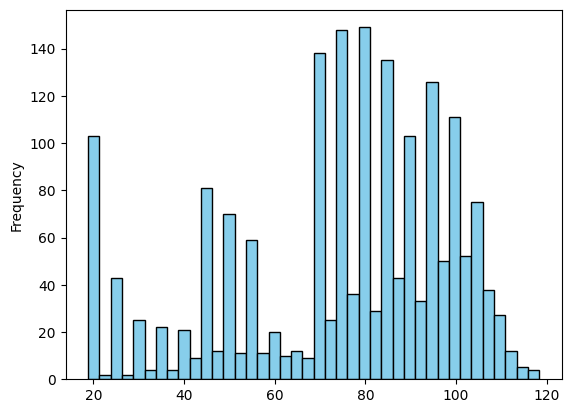

In [62]:
churn_yes = churn[churn["Churn"] == "Yes"]
churn_yes["MonthlyCharges"].plot(kind="hist",
    bins=40,
    edgecolor="black",
    color="skyblue")
plt.show()

In [63]:
churn_yes["MonthlyCharges"].mean()

np.float64(74.44133226324237)

In [64]:
churn.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'Customer_Type'],
      dtype='object')

In [65]:
# Which payment methods have the highest churn?

churn.PaymentMethod.groupby(churn.Churn).value_counts(normalize=True)

Churn  PaymentMethod            
No     Mailed check                 0.252029
       Electronic check             0.250097
       Credit card (automatic)      0.249324
       Bank transfer (automatic)    0.248550
Yes    Electronic check             0.573034
       Mailed check                 0.164794
       Bank transfer (automatic)    0.138042
       Credit card (automatic)      0.124131
Name: proportion, dtype: float64

In [66]:
payment_high_churn_electronic = ((churn["PaymentMethod"] == "Electronic check") & (churn["Churn"] == "Yes")).sum()

In [67]:
total_count_payment = churn.PaymentMethod.groupby(churn.Churn).value_counts()
total_count_payment

Churn  PaymentMethod            
No     Mailed check                 1304
       Electronic check             1294
       Credit card (automatic)      1290
       Bank transfer (automatic)    1286
Yes    Electronic check             1071
       Mailed check                  308
       Bank transfer (automatic)     258
       Credit card (automatic)       232
Name: count, dtype: int64

In [68]:
# people who use electronic check payment method has a high rate of churn
payment_high_churn_electronic/1869 * 100

np.float64(57.30337078651685)

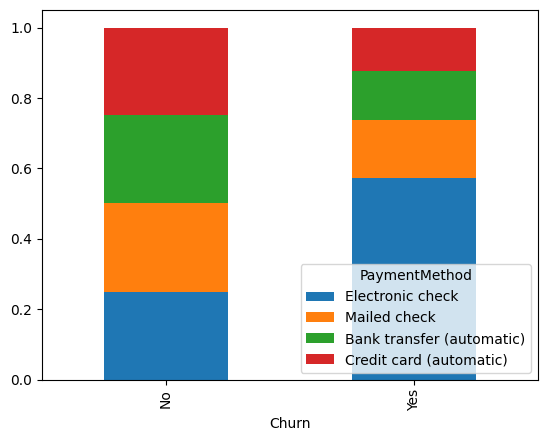

In [69]:
data = churn.groupby("Churn")["PaymentMethod"].value_counts(normalize=True).unstack()

data = data[["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"]]

data.plot(kind="bar", stacked=True)

plt.show()

In [70]:
# Which services (internet type, tech support, etc.) are linked to churn?

total_yes_internetservice = churn.groupby("Churn")["InternetService"].value_counts()["Yes"]
total_yes_internetservice

,count
InternetService,
Fiber optic,1297
DSL,459
No,113


In [71]:
# customer who use a fiber optic calen network service having a high rate of churn
fiber_optic_yes = churn[(churn["InternetService"] == "Fiber optic") & (churn["Churn"] == "Yes")].groupby("InternetService").size()
fiber_optic_yes / 1869 * 100

,0
InternetService,
Fiber optic,69.395399


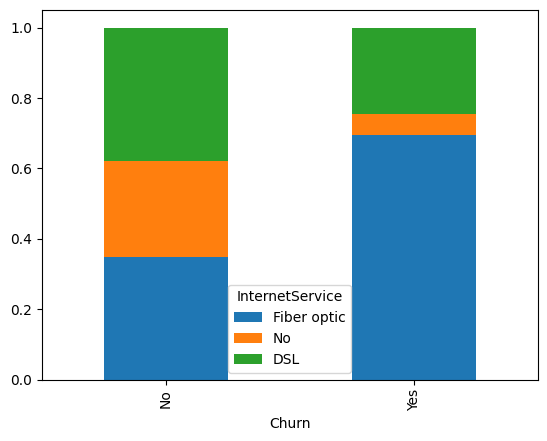

In [72]:
data = churn.groupby("Churn")["InternetService"].value_counts(normalize=True).unstack()
data = data[["Fiber optic","No","DSL"]]
data.plot(kind="bar", stacked=True)
plt.show()